# Castrate-sensitive cohort (Zhang et al.): are the AT score and eTTP predictive of PSA progression?

**Question.** Using only first-cycle PSA, are the AT score or the eTTP correlated with, or prognostic of (Cox), time to PSA progression in the 16-patient castrate-sensitive cohort? The Lotka–Volterra model, solver, optimiser settings and parameter block are imported **unchanged** from `patients/first_cycle_fitting.py`; only data preparation is cohort-specific (`patients/castrate_sensitive.py`).

## Headline

**In the primary specification neither biomarker is predictive of PSA progression.** Over the full cohort (n = 16, 5 events) the AT score has HR 0.93 per +1 SD (95% CI 0.37–2.30; P = .87) and Harrell C = 0.54 (permutation P = .40); the eTTP is the same (HR 0.91, 0.36–2.33; C = 0.55). With the 6 events obtained by reconciling two discrepant outcomes (below), HR 0.98 and 1.13. The data exclude a strong protective effect (HR below about 0.37 per SD) but cannot exclude a moderate one.

Two analysis sets that discard the 3–4 fastest-turnover patients (**including 2 of the 5 events**) lean in the expected direction (C = 0.78, log-rank P = .08 / .07), but they rest on 3 events, the Cox model is quasi-separated (HR 0.03, CI 0.00–19.9; Wald P = .29), and nothing reaches P < .05 by Wald test in any of the 92 estimable specifications (of 96 pre-declared).

For context, in the same patients the **empirical PSA nadir** (HR 10.4 per SD, 95% CI 1.27–86, P = .029), time to nadir, baseline PSA and **clinical high-risk category** (HR 3.14, 1.09–9.04, P = .034) are nominally associated with progression. These are uncorrected for multiplicity and rest on 5 events, so they are descriptive, but the ordering is the reverse of the one reported for the other cohorts.

## What was fixed before any association was computed

| Choice | Decision | Basis |
|---|---|---|
| Time origin | t = 0 at the first ADT dose; if day-0 PSA is missing, the latest pre-treatment PSA is carried to t = 0 (5 patients); other Cycle-0 rows dropped | matches the other cohorts (t = 0 is treatment start). The literal "first PSA = day 0" reading is run as a sensitivity |
| NaN-PSA rows | **kept** (drug schedule only; the fit ignores them via `nan_policy='omit'`) | all 16 patients have drug switches recorded on rows with no PSA |
| Drug state | ADT only | rule fixed from fit quality alone: union if ADT-only median R² < 0.5 or < 12/16 patients reach R² > 0.5. Observed 0.80 and 16/16, so ADT; union run as a sensitivity |
| Normalisation, priors, K | first measurement; fR = 1e-2, cost = 0.01; K fitted on [2.5, 5] | the harmonised protocol recommended for the other two cohorts. Bruchovsky-style priors run as a sensitivity |
| AT score | `calc_delta_benefit`, constant κ = 0.2 | no outcome-window quantity (`n_crit` is not used) |
| eTTP | `predict_atx_ttp`, τ = 30 d | the published eTTP (`predict_clinical_ttp`) needs PSA up to clinical TTP and cannot be computed from first-cycle data |
| Outcomes | `progression_outcomes.tsv` as supplied (primary) **and** reconciled to the workbook's Summary tab | the two disagree for patients 102 and 116 (section 1) |
| Statistics | univariable Cox on the standardised score (HR per +1 SD; HR < 1 = protective), Harrell C with permutation P, Spearman, AUC, median-split KM / log-rank | same framework as the other cohorts; HR reported as fitted, not as a reciprocal. A multivariable model is omitted: 5 events |

**Disclosure.** The inclusion cascade (section 4) was inspected, including which patients carry the events, *before* any association was computed. Analysis sets A, B and C were declared after seeing it, and before any association. The 96-cell grid in section 7 contains every combination of the choices above and nothing else.

## Analysis sets

* **A, convention-matched.** Model predicts CT progression, turnover below the AT-score pole, R² > 0.5 (the filters used in the other cohorts).
* **B, AT-score domain.** Turnover below the pole and R² > 0.5. The AT score does not need CT progression.
* **C, full cohort.** All 16 patients. Where the formulae diverge (turnover at or above the pole: the resistant population is held indefinitely; or no CT progression, for eTTP) the biomarker is +∞ and the patient ranks highest. Cox uses the rank-normalised score.


In [1]:
import os, sys, warnings, itertools
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, mannwhitneyu
warnings.filterwarnings("ignore")

ROOT = os.path.dirname(os.getcwd())                 # this notebook lives in paper_figures/
for sub in ("utils", "patients", "analysis"):
    sys.path.insert(0, os.path.join(ROOT, sub))
import castrate_sensitive as cs
import castrate_sensitive_stats as st
from myUtils import test_progression, ExtractTreatmentFromDf
from odeModels import LotkaVolterraModel
from first_cycle_fitting import SOLVER_KWS

BLUE, GREEN, RED, GOLD, GREY = "#0044AA", "#4c9150", "#a80303", "#c28d32", "#7a7a7a"
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 9.5, "axes.labelsize": 9, "figure.dpi": 110,
                     "savefig.dpi": 300, "savefig.bbox": "tight", "legend.frameon": False})
pd.set_option("display.width", 220, "display.max_columns", 40)
OUT = os.path.join(ROOT, "analysis"); os.makedirs(OUT, exist_ok=True)

## 1. Data audit

In [2]:
tabs = cs.load_tabs(); summary = cs.load_summary(); outcomes = cs.load_outcomes()
assert set(tabs) == set(outcomes.index), "tab ids and outcome ids differ"

rows = []
for pid, t in tabs.items():
    d = t.reset_index(drop=True)
    drugs = d[["ADT", "Abi", "ARSI"]].fillna(0)
    switch_on_nan_psa = int((d.PSA.isna() & (drugs.diff().abs().sum(axis=1) > 0)).sum())
    day0 = d[d.Days == 0]
    rows.append(dict(PatientId=pid, n_rows=len(d), n_PSA=int(d.PSA.notna().sum()),
                     cycle0_pretreatment_rows=int((d.Cycle == 0).sum()),
                     day0_PSA_missing=bool(len(day0) and day0.PSA.isna().all()),
                     drug_switches_on_NaN_PSA_rows=switch_on_nan_psa,
                     other_agent_used=bool(((d.Abi == 1) | (d.ARSI == 1)).any()),
                     agent=d.label_agent.iloc[0] or ("Abi" if (d.Abi == 1).any() else "")))
audit = pd.DataFrame(rows).set_index("PatientId")
print(audit.to_string())
print(f"\npatients: {len(audit)} | with pre-treatment (Cycle 0) rows: {(audit.cycle0_pretreatment_rows>0).sum()} | "
      f"day-0 PSA missing: {audit.day0_PSA_missing.sum()} | with drug switches recorded on NaN-PSA rows: "
      f"{(audit.drug_switches_on_NaN_PSA_rows>0).sum()} | exposed to Abi/ARSI: {audit.other_agent_used.sum()}")

           n_rows  n_PSA  cycle0_pretreatment_rows  day0_PSA_missing  drug_switches_on_NaN_PSA_rows  other_agent_used agent
PatientId                                                                                                                  
102             9      7                         0             False                              2              True   Abi
103            21     17                         1              True                              4              True   Abi
104             9      8                         1             False                              1              True   Abi
105            10      7                         0             False                              3              True   Abi
106             8      6                         1              True                              2              True   Abi
107             7      6                         0             False                              1              True  Enza
108     

In [3]:
as_supplied, reconciled, recon_audit = cs.reconcile_outcomes(outcomes, summary)
print("Outcome file (progression_outcomes.tsv) vs the workbook's own Summary tab:\n")
print(recon_audit.to_string())
bad = recon_audit[recon_audit.TTE_mismatch | recon_audit.status_mismatch]
print(f"\nMISMATCHES: {list(bad.index)}")
print(f"  events as supplied: {int(as_supplied.Event.sum())} / {len(as_supplied)}   |   after reconciling to the Summary tab: {int(reconciled.Event.sum())} / {len(reconciled)}")
for pid in bad.index:
    print(f"  patient {pid}: TSV (TTE={int(as_supplied.loc[pid,'TTE'])}, status={'progressed' if as_supplied.loc[pid,'Event'] else 'not'}) "
          f"-> Summary PSA progression = {int(summary.loc[pid,'PSA progression (days)'])} d"
          + ("  [the TSV value equals the Summary rPFS, not PSA progression]" if recon_audit.loc[pid,'tsv_equals_rPFS'] else ""))

Outcome file (progression_outcomes.tsv) vs the workbook's own Summary tab:

           tsv_TTE  tsv_Event  summary_PSA_progression  summary_rPFS  TTE_mismatch  status_mismatch  tsv_equals_rPFS
PatientId                                                                                                           
102            840          1                    462.0         840.0          True            False             True
106           1296          1                   1296.0           NaN         False            False            False
107            849          1                    849.0         849.0         False            False             True
109            623          1                    623.0         889.0         False            False            False
111            350          1                    350.0         735.0         False            False            False
116            803          0                    803.0           NaN         False             True      

**Two outcome discrepancies need confirming.** Patient 102: the TSV gives 840 d, which is the Summary tab's **rPFS**; its PSA progression is 462 d. Patient 116: the Summary records PSA progression at 803 d, but the TSV codes it as *not progressed* at 803 d. Both are analysed (TSV as supplied = primary; reconciled = sensitivity) and neither is silently preferred. Reconciling moves 5 events to 6.

## 2. Drug state: ADT only or the union of agents?

In [4]:
def fit_all(origin, drug, priors):
    rows = []
    for pid, t in tabs.items():
        rec = cs.build_record(t, origin=origin, drug=drug)
        v = cs.fit_record(rec, priors)
        rows.append(dict(PatientId=pid, origin=origin, drug=drug, priors=priors,
                         baseline_from_pretreatment=bool(rec.baseline_from_pretreatment.iloc[0]), **v))
    return pd.DataFrame(rows)

dq = {d: fit_all("treatment", d, "Zhang-style") for d in ("ADT", "union")}
cmp_ = dq["ADT"][["PatientId", "RSquared", "turnover", "K"]].merge(dq["union"][["PatientId", "RSquared", "turnover", "K"]],
                                                                   on="PatientId", suffixes=("_ADT", "_union"))
print(cmp_.round(3).to_string(index=False))
for d in ("ADT", "union"):
    r = dq[d].RSquared
    print(f"{d:6s}: median R2 = {r.median():.3f} | R2 > 0.5: {(r>0.5).sum()}/{len(r)} | R2 < 0: {(r<0).sum()}")
RULE_MEDIAN, RULE_PASS = 0.5, 12
use_union = (dq["ADT"].RSquared.median() < RULE_MEDIAN) or ((dq["ADT"].RSquared > 0.5).sum() < RULE_PASS)
PRIMARY_DRUG = "union" if use_union else "ADT"
print(f"\nDecision rule (fixed from fit quality alone, before any outcome was examined): switch to the union if ADT-only "
      f"median R2 < {RULE_MEDIAN} or fewer than {RULE_PASS}/16 patients reach R2 > 0.5.  ->  primary drug state = {PRIMARY_DRUG}")

 PatientId  RSquared_ADT  turnover_ADT  K_ADT  RSquared_union  turnover_union  K_union
       102         0.677         0.406  5.000           0.694           0.383    5.000
       103         0.910         0.912  5.000           0.934           0.858    5.000
       104         0.687         0.374  5.000           0.687           0.374    5.000
       105         0.902         1.000  5.000           0.901           1.000    5.000
       106         0.790         1.000  5.000           0.790           1.000    5.000
       107         0.800         0.449  5.000           0.800           0.449    5.000
       108         0.884         0.690  4.864           0.884           0.690    4.864
       109         0.925         0.382  5.000           0.925           0.353    5.000
       110         0.703         0.727  5.000           0.761           0.573    5.000
       111         0.921         1.000  5.000           0.921           1.000    5.000
       112         0.772         0.572  5.0

**ADT-only is used.** Fit quality is good under both definitions (median R² 0.80 vs 0.795; 16/16 above 0.5), so the brief's trigger for the union (poor fits, or shrinkage with no drug) is not met on fit quality. All 16 patients were exposed to Abi or an ARSI (section 1), so the union is kept as a sensitivity.

## 3. First-cycle fits (primary specification)

In [5]:
PRIMARY = dict(origin="treatment", drug=PRIMARY_DRUG, priors="Zhang-style")
prim = fit_all(**PRIMARY).set_index("PatientId")
print("Primary specification:", PRIMARY, "| normalisation: first measurement | K fitted on [2.5, 5] | kappa = 0.2")
print(prim[["n_psa_points", "RSquared", "turnover", "K", "baseline_from_pretreatment", "success"]].round(3).to_string())
print(f"\nK at upper bound 5.0: {(prim.K>4.999).sum()} | at lower bound 2.5: {(prim.K<2.501).sum()} | interior: {((prim.K>2.501)&(prim.K<4.999)).sum()}")
print(f"turnover at upper bound 1.0: {(prim.turnover>0.9999).sum()} | median R2 = {prim.RSquared.median():.3f}")

Primary specification: {'origin': 'treatment', 'drug': 'ADT', 'priors': 'Zhang-style'} | normalisation: first measurement | K fitted on [2.5, 5] | kappa = 0.2
           n_psa_points  RSquared  turnover      K  baseline_from_pretreatment  success
PatientId                                                                              
102                   7     0.677     0.406  5.000                       False     True
103                  17     0.910     0.912  5.000                        True     True
104                   7     0.687     0.374  5.000                       False     True
105                   7     0.902     1.000  5.000                       False     True
106                   6     0.790     1.000  5.000                        True     True
107                   6     0.800     0.449  5.000                       False     True
108                  13     0.884     0.690  4.864                       False     True
109                   5     0.925     0.382  5.00

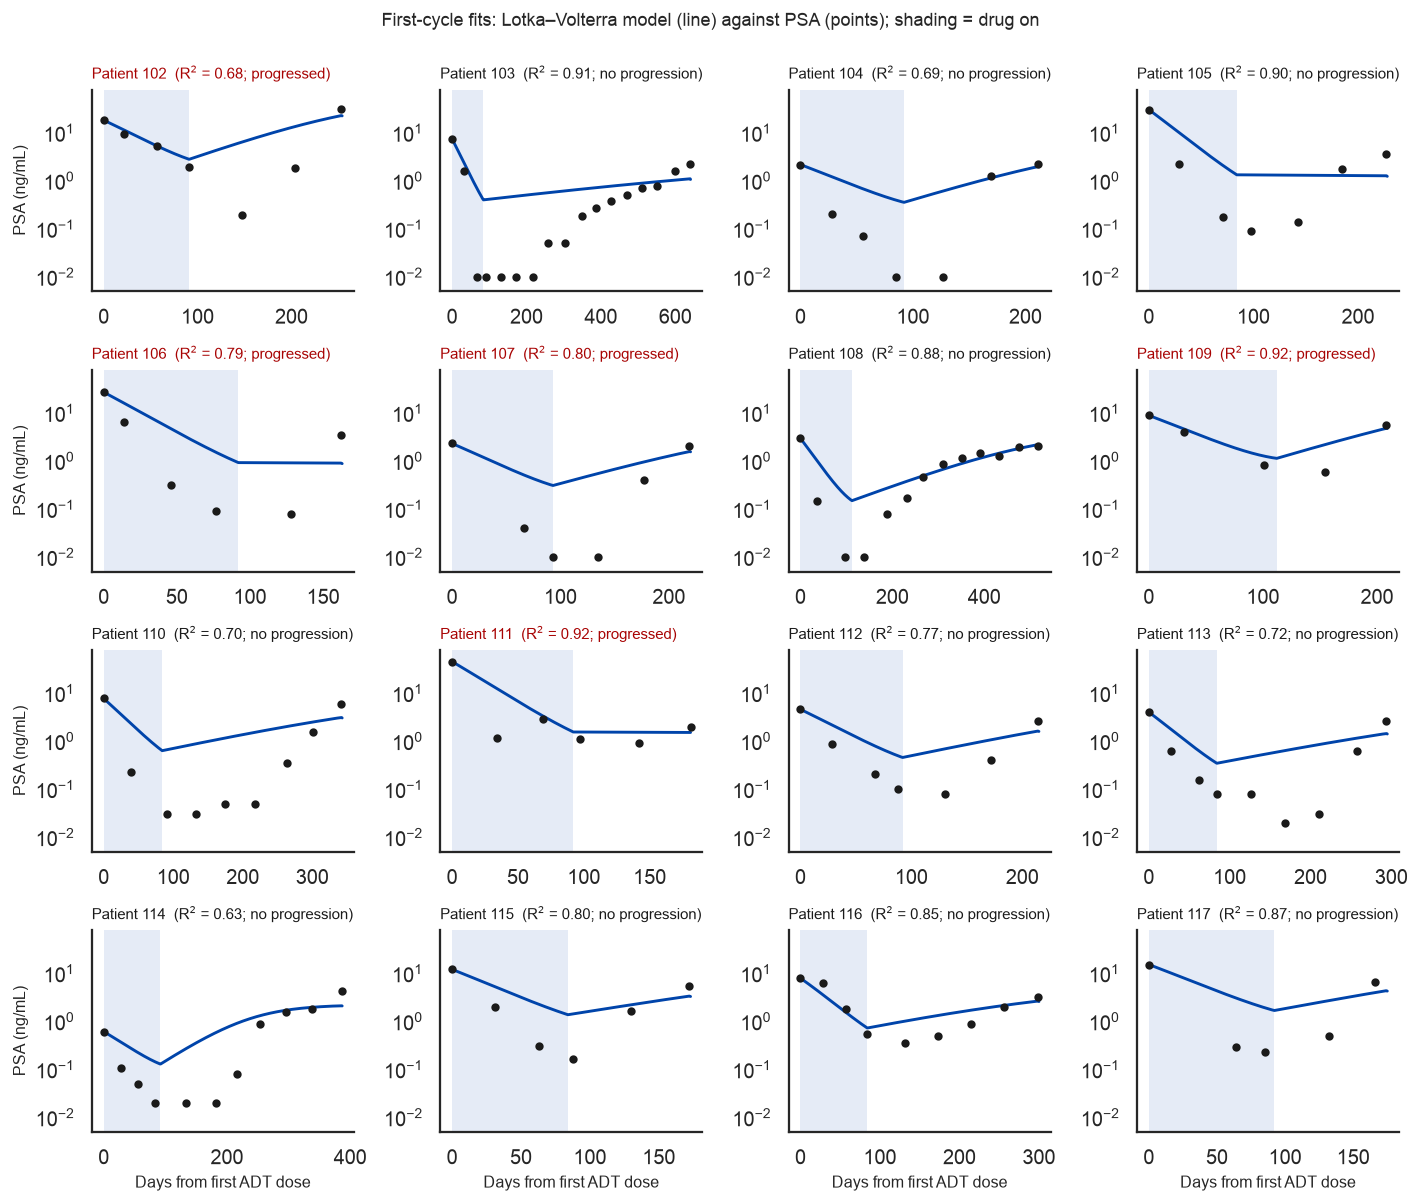

In [6]:
def model_curve(v, rec):
    m = LotkaVolterraModel(); m.SetParams(**v)
    m.Simulate(treatmentScheduleList=ExtractTreatmentFromDf(rec), **SOLVER_KWS)
    return m.resultsDf.Time.values, m.resultsDf.TumourSize.values

fig, axs = plt.subplots(4, 4, figsize=(11, 9.2), sharex=False)
for ax, pid in zip(axs.flat, sorted(tabs)):
    rec = cs.build_record(tabs[pid], origin="treatment", drug=PRIMARY_DRUG)
    base = rec.PSA_raw.dropna().iloc[0]
    t, n = model_curve(prim.loc[pid].to_dict(), rec)
    on = rec.DrugConcentration.values; tt = rec.Time.values
    for i in range(len(rec) - 1):
        if on[i] > 0: ax.axvspan(tt[i], tt[i + 1], color=BLUE, alpha=0.10, lw=0)
    ax.plot(t, np.maximum(n * base, 0.005), color=BLUE, lw=1.6)
    ok = rec.PSA_raw.notna(); ax.plot(tt[ok], rec.PSA_raw[ok], "o", color="k", ms=3.6, zorder=3)
    ax.set_yscale("log"); ax.set_ylim(0.005, 80)
    ev = as_supplied.loc[pid, "Event"]
    ax.set_title(f"Patient {pid}  (R$^2$ = {prim.loc[pid,'RSquared']:.2f}; " + ("progressed" if ev else "no progression") + ")",
                 color=RED if ev else "k", fontsize=8.2, loc="left")
    if pid in (102, 106, 110, 114): ax.set_ylabel("PSA (ng/mL)")
    if pid >= 114: ax.set_xlabel("Days from first ADT dose")
fig.suptitle("First-cycle fits: Lotka–Volterra model (line) against PSA (points); shading = drug on", y=1.0, fontsize=10)
fig.tight_layout(); fig.savefig(os.path.join(OUT, "castrate_sensitive_fits.png")); plt.show()

In [7]:
# Linear-space R2 is dominated by the baseline-to-end contrast and does not see a log-scale miss of the nadir.
rows = []
for pid in sorted(tabs):
    rec = cs.build_record(tabs[pid], origin="treatment", drug=PRIMARY_DRUG)
    base = rec.PSA_raw.dropna().iloc[0]
    t, n = model_curve(prim.loc[pid].to_dict(), rec)
    c1 = rec[(rec.CycleId <= 1) & rec.PSA_raw.notna()]
    obs_nadir = float(c1.PSA_raw.min())
    model_min = float(n[t <= c1.Time.max()].min() * base)
    pred = np.interp(c1.Time.values, t, n * base)
    log_err = np.log10(np.maximum(pred, 0.01)) - np.log10(np.maximum(c1.PSA_raw.values, 0.01))
    rows.append(dict(PatientId=pid, observed_nadir=obs_nadir, model_minimum=model_min,
                     miss_factor=model_min / obs_nadir, linear_R2=prim.loc[pid, "RSquared"],
                     rmse_log10=float(np.sqrt(np.mean(log_err ** 2)))))
NM = pd.DataFrame(rows).set_index("PatientId")
print(NM.round(3).to_string())
print(f"\nModel nadir / observed nadir: median {NM.miss_factor.median():.1f}x | >= 10x in {(NM.miss_factor>=10).sum()}/16 patients | >= 3x in {(NM.miss_factor>=3).sum()}/16")
print(f"Median RMSE on the log10 scale = {NM.rmse_log10.median():.2f} (i.e. a typical factor of {10**NM.rmse_log10.median():.1f}x) while median linear R2 = {NM.linear_R2.median():.2f}")
print("Note: observed nadirs are floored by the assay (<0.02 ng/mL reported as 0.01), so the miss factors are lower bounds where the nadir is at the floor.")

           observed_nadir  model_minimum  miss_factor  linear_R2  rmse_log10
PatientId                                                                   
102                  0.20          2.832       14.160      0.677       0.713
103                  0.01          0.404       40.439      0.910       1.047
104                  0.01          0.359       35.882      0.687       1.106
105                  0.09          1.308       14.530      0.902       0.806
106                  0.08          0.926       11.570      0.790       0.911
107                  0.01          0.311       31.127      0.800       1.154
108                  0.01          0.150       15.040      0.884       0.610
109                  0.60          1.143        1.906      0.925       0.298
110                  0.03          0.640       21.324      0.703       1.103
111                  0.93          1.548        1.665      0.921       0.476
112                  0.08          0.462        5.770      0.772       0.586

**Linear R² hides a large miss of the nadir.** On the log scale the model's minimum is a median **12.9×** the observed nadir (at least 10× in 9 of 16 patients) and the typical log₁₀ error corresponds to a factor of 5.6, while median linear R² is 0.80. The R² > 0.5 filter inherited from the other cohorts therefore does not screen out these fits. With `rS` and `dD` fixed, a 1–2 log decline can only be approximated by pushing turnover to its bound, which happens for 3 patients (105, 106 and 111 reach the turnover bound of 1.0; with 103, four patients sit above the pole). The two patients with the *smallest* misses (109, 111) are two of the five who progressed, and they have the two highest observed nadirs.

## 4. Biomarkers and inclusion cascade

In [8]:
scored = st.score_fits(prim.reset_index(), cost=cs.PRIORS[PRIMARY["priors"]]["cost"]).set_index("PatientId")
scored = scored.join(as_supplied.add_suffix("_tsv")).join(reconciled.add_suffix("_rec"))
casc = pd.DataFrame({
    "patients": [16, int(scored.model_progresses.sum()), int((~scored.above_pole).sum()), int(scored.R2_ok.sum())],
}, index=["fitted", "model predicts CT progression", "turnover below AT-score pole", "R2 > 0.5 (or undefined)"])
print(scored[["turnover", "K", "RSquared", "model_progresses", "above_pole", "AT_score", "eTTP", "Event_tsv", "TTE_tsv"]].round(3).to_string())
print()
sets = pd.DataFrame({s: dict(patients=int(scored["set_"+s].sum()),
                             events_tsv=int(scored.loc[scored["set_"+s], "Event_tsv"].sum()),
                             events_reconciled=int(scored.loc[scored["set_"+s], "Event_rec"].sum())) for s in "ABC"}).T
sets.index = ["A  convention-matched (progression + pole + R2)", "B  AT-score domain (pole + R2)", "C  full cohort (+inf above pole)"]
print(sets.to_string())
lost = scored[~scored.set_A & (scored.Event_tsv == 1)].index.tolist()
print(f"\nEvents lost by the convention filters (set A), TSV outcomes: {lost}  -> all are patients whose fitted turnover sits above the pole")

           turnover      K  RSquared  model_progresses  above_pole  AT_score      eTTP  Event_tsv  TTE_tsv
PatientId                                                                                                 
102           0.406  5.000     0.677              True       False     0.517   466.575          1      840
103           0.912  5.000     0.910             False        True       inf       inf          0     1987
104           0.374  5.000     0.687              True       False     0.477   431.161          0     1933
105           1.000  5.000     0.902             False        True       inf       inf          0     1963
106           1.000  5.000     0.790             False        True       inf       inf          1     1296
107           0.449  5.000     0.800              True       False     0.582   525.730          1      849
108           0.690  4.864     0.884              True       False     2.006  1849.046          0     1661
109           0.382  5.000     0.925 

The convention filters would keep 11 of 16 patients and only 3 of 5 events. The two events lost (106, 111) are both patients whose turnover is fitted above the pole, i.e. whose AT score is formally infinite. That is why the three analysis sets are reported side by side.

## 5. Primary association analysis

In [9]:
def run_sets(scored, outs, perm_n=5000):
    rows = []
    for oname, o in outs.items():
        for sset in "ABC":
            for sc in ("AT_score", "eTTP"):
                r = st.analyse(scored, o, sc, sset, perm_n=perm_n); r.update(outcomes=oname, set=sset, score=sc); rows.append(r)
    return pd.DataFrame(rows)
OUTS = {"TSV as supplied": as_supplied, "Summary-reconciled": reconciled}
P = run_sets(scored, OUTS)
cols = ["outcomes", "set", "score", "N", "events", "HR", "lo", "hi", "p_wald", "p_lr", "C", "p_C_one", "p_C_two", "rho_T", "p_rho", "AUC_nonprog", "p_auc"]
print("HR is per +1 SD of the score (set C: rank-normalised); HR < 1 = higher score -> longer time to PSA progression (expected direction).")
print("C = Harrell concordance for 'higher score -> longer time' (0.5 = chance); permutation p for C is one-sided (expected direction) and two-sided.\n")
print(P[cols].round(3).to_string(index=False))
P.to_csv(os.path.join(OUT, "castrate_sensitive_primary_results.csv"), index=False)

HR is per +1 SD of the score (set C: rank-normalised); HR < 1 = higher score -> longer time to PSA progression (expected direction).
C = Harrell concordance for 'higher score -> longer time' (0.5 = chance); permutation p for C is one-sided (expected direction) and two-sided.

          outcomes set    score  N  events    HR    lo     hi  p_wald  p_lr     C  p_C_one  p_C_two  rho_T  p_rho  AUC_nonprog  p_auc
   TSV as supplied   A AT_score 11       3 0.029 0.000 19.864   0.288 0.063 0.778    0.089    0.162  0.364  0.272        0.750  0.277
   TSV as supplied   A     eTTP 11       3 0.035 0.000 16.959   0.288 0.063 0.778    0.089    0.162  0.364  0.272        0.750  0.277
   TSV as supplied   B AT_score 12       3 0.028 0.000 19.702   0.285 0.056 0.786    0.082    0.154  0.217  0.499        0.778  0.193
   TSV as supplied   B     eTTP 12       3 0.023 0.000 24.407   0.288 0.057 0.786    0.082    0.156  0.112  0.729        0.778  0.196
   TSV as supplied   C AT_score 16       5 0.925 0.37

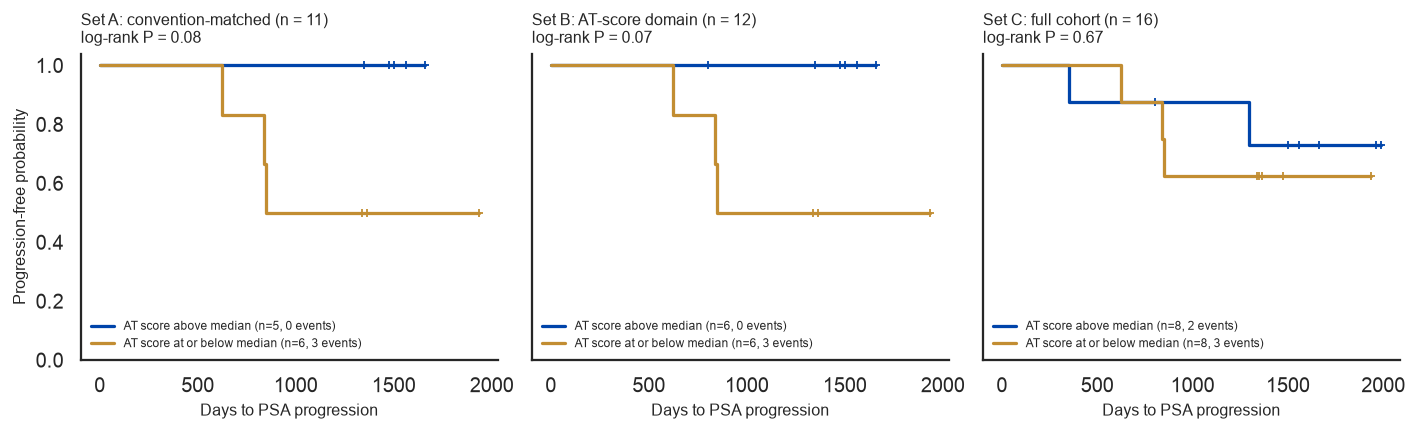

In [10]:
from lifelines import KaplanMeierFitter
fig, axs = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for ax, (sset, title) in zip(axs, [("A", "Set A: convention-matched (n = 11)"), ("B", "Set B: AT-score domain (n = 12)"), ("C", "Set C: full cohort (n = 16)")]):
    sub = scored[scored["set_" + sset]].join(as_supplied, how="inner")
    s = st._rank_inf(sub.AT_score.values); hi = s > np.median(s)
    for mask, lab, col in [(hi, "AT score above median", BLUE), (~hi, "AT score at or below median", GOLD)]:
        if mask.sum() == 0: continue
        km = KaplanMeierFitter().fit(sub.TTE[mask], sub.Event[mask], label=f"{lab} (n={mask.sum()}, {int(sub.Event[mask].sum())} events)")
        km.plot_survival_function(ax=ax, ci_show=False, color=col, lw=1.8, show_censors=True, censor_styles={"ms": 4})
    lr = st.logrank_median_split(sub.AT_score.values, sub.TTE.values, sub.Event.values)
    ax.set_title(title + f"\nlog-rank P = {lr['p']:.2f}", fontsize=8.6, loc="left")
    ax.set_xlabel("Days to PSA progression"); ax.legend(fontsize=6.4, loc="lower left")
axs[0].set_ylabel("Progression-free probability"); axs[0].set_ylim(0, 1.04)
fig.tight_layout(); fig.savefig(os.path.join(OUT, "castrate_sensitive_km.png")); plt.show()

**Reading the primary table and figure.** Over the full cohort (set C) there is no association with any outcome measure: HR ≈ 0.9, C ≈ 0.54, Spearman ρ with time = +0.20 (P = .46), AUC for non-progressors = 0.53 (P = .88). Sets A and B show a protective *direction* (non-progressors have higher scores; C = 0.78–0.79), but the above-median group (5–6 patients) has **zero** events once 106 and 111 are removed, so the Cox HR is quasi-separated (point estimate 0.03, CI 0.00–19.9), the Wald P is .29, and the log-rank P is .08 / .07. These sets are conditioned on a model-derived exclusion that removes 40% of the events; they should not be read as independent support.

The eTTP and the AT score give an identical ranking in sets A and B, so their rank-based statistics coincide there. In set C they differ only slightly: patient 116 has a finite AT score but no CT progression, so its eTTP is +∞.

## 6. Empirical PSA metrics and clinical risk as comparators

In [11]:
recs = {pid: cs.build_record(t, origin="treatment", drug=PRIMARY_DRUG) for pid, t in tabs.items()}
M = pd.DataFrame({pid: st.first_cycle_metrics(r) for pid, r in recs.items()}).T
M["Clinical_high_risk"] = (summary["risk/latitude"].reindex(M.index).str.strip().str.lower() == "high").astype(int)
M["De_novo_M1"] = (summary["de novo M1"].reindex(M.index).str.strip().str.upper() == "Y").astype(int)
M["AT_score"] = scored.AT_score; M["eTTP"] = scored.eTTP
M["nadir_relative_to_baseline"] = M.PSA_Nadir / M.Baseline_PSA; M["turnover"] = scored.turnover

def comparators(outs, label):
    rows = []
    for col in ["AT_score", "eTTP", "Baseline_PSA", "PSA_Nadir", "Time_to_Nadir", "PSA_Doubling_Time_days", "PSA_Velocity_per_day", "Clinical_high_risk", "De_novo_M1"]:
        sub = M[[col]].join(outs).dropna(subset=[col])
        s = sub[col].values.astype(float); T = sub.TTE.values; E = sub.Event.values.astype(int)
        cx = st.cox_uni(s, T, E, use_rank=col in ("AT_score", "eTTP")); c = st.perm_c(s, T, E, n=5000)
        rows.append(dict(outcomes=label, covariate=col, N=len(sub), events=int(E.sum()), HR_per_SD=cx["HR"], lo=cx["lo"], hi=cx["hi"],
                         p_wald=cx["p_wald"], C_higher_value_longer_time=c["C"], p_C_two=c["p_two"]))
    return pd.DataFrame(rows)
CMP = pd.concat([comparators(o, k) for k, o in OUTS.items()], ignore_index=True)
print("All covariates oriented the same way: HR > 1 means a higher value is associated with EARLIER progression; C < 0.5 likewise.\n")
print(CMP.round(3).to_string(index=False))
CMP.to_csv(os.path.join(OUT, "castrate_sensitive_comparators.csv"), index=False)
hr = M.Clinical_high_risk.astype(bool)
print(f"\nHigh-risk patients: {sorted(M.index[hr])}; of these progressed (TSV): {sorted(as_supplied.index[(as_supplied.Event==1) & hr.reindex(as_supplied.index)])}")
print(f"Median fitted turnover  High risk = {scored.turnover[hr].median():.2f}  vs  Low risk = {scored.turnover[~hr].median():.2f};  "
      f"AT score by risk, Mann-Whitney P = {mannwhitneyu(st._rank_inf(M.AT_score[hr]), st._rank_inf(M.AT_score[~hr])).pvalue:.2f}")

All covariates oriented the same way: HR > 1 means a higher value is associated with EARLIER progression; C < 0.5 likewise.

          outcomes              covariate  N  events  HR_per_SD    lo     hi  p_wald  C_higher_value_longer_time  p_C_two
   TSV as supplied               AT_score 16       5      0.925 0.372  2.302   0.867                       0.540    0.818
   TSV as supplied                   eTTP 16       5      0.914 0.358  2.330   0.850                       0.548    0.758
   TSV as supplied           Baseline_PSA 16       5      2.501 1.016  6.158   0.046                       0.274    0.116
   TSV as supplied              PSA_Nadir 16       5     10.440 1.268 85.953   0.029                       0.226    0.043
   TSV as supplied          Time_to_Nadir 16       5      2.349 1.001  5.512   0.050                       0.194    0.033
   TSV as supplied PSA_Doubling_Time_days 13       2      0.455 0.043  4.817   0.513                       0.667    0.557
   TSV as supplied   

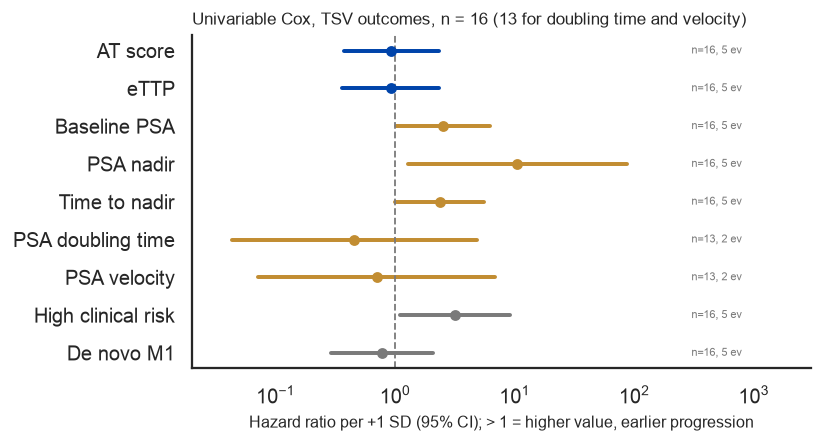

In [12]:
lab = {"AT_score": "AT score", "eTTP": "eTTP", "Baseline_PSA": "Baseline PSA", "PSA_Nadir": "PSA nadir", "Time_to_Nadir": "Time to nadir",
       "PSA_Doubling_Time_days": "PSA doubling time", "PSA_Velocity_per_day": "PSA velocity", "Clinical_high_risk": "High clinical risk", "De_novo_M1": "De novo M1"}
d = CMP[CMP.outcomes == "TSV as supplied"].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(6.4, 3.5))
for i, r in d.iterrows():
    col = BLUE if r.covariate in ("AT_score", "eTTP") else (GOLD if r.covariate not in ("Clinical_high_risk", "De_novo_M1") else GREY)
    ax.plot([r.lo, r.hi], [i, i], color=col, lw=2.2, solid_capstyle="round"); ax.plot(r.HR_per_SD, i, "o", color=col, ms=5, zorder=3)
    ax.text(300, i, f"n={r.N}, {r.events} ev", va="center", fontsize=6.3, color=GREY)
ax.axvline(1, color=GREY, ls="--", lw=1); ax.set_xscale("log"); ax.set_xlim(0.02, 3000)
ax.set_yticks(range(len(d))); ax.set_yticklabels([lab[c] for c in d.covariate]); ax.invert_yaxis()
ax.set_xlabel("Hazard ratio per +1 SD (95% CI); > 1 = higher value, earlier progression")
ax.set_title("Univariable Cox, TSV outcomes, n = 16 (13 for doubling time and velocity)", loc="left")
fig.tight_layout(); fig.savefig(os.path.join(OUT, "castrate_sensitive_forest.png")); plt.show()

**The comparators.** PSA nadir, baseline PSA, time to nadir and clinical high-risk category each reach nominal P ≈ .03–.05 in this cohort; the AT score and eTTP do not. Four of the five high-risk patients progressed against 1 of 11 low-risk patients, so clinical risk alone separates the outcomes better than either biomarker, and fitted turnover is *lower* in high-risk patients (median 0.45 vs 0.69), the expected (protective) ordering, although not significantly so (P = .21). With 5–6 events none of this supports adjustment (a bivariable model is not estimable in a stable way), the intervals are very wide (nadir 1.27–86), 9 covariates are tested in each of 2 outcome versions without correction, and the doubling-time and velocity estimates rest on 13 patients and 2–3 events. These comparators are context, not findings.

## 7. Pre-declared sensitivity grid

In [13]:
FITV = {k: fit_all(*k) for k in itertools.product(["treatment", "first_psa"], ["ADT", "union"], ["Zhang-style", "Bruchovsky-style"])}
GRID = []
for (origin, drug, priors), fdf in FITV.items():
    sc_ = st.score_fits(fdf, cost=cs.PRIORS[priors]["cost"]).set_index("PatientId")
    for oname, o in OUTS.items():
        for sset in "ABC":
            for scn in ("AT_score", "eTTP"):
                r = st.analyse(sc_, o, scn, sset, perm_n=3000)
                r.update(origin=origin, drug=drug, priors=priors, outcomes=oname, set=sset, score=scn,
                         n_above_pole=int(sc_.above_pole.sum())); GRID.append(r)
G = pd.DataFrame(GRID); G.to_csv(os.path.join(OUT, "castrate_sensitive_spec_grid.csv"), index=False)
ok = G.dropna(subset=["HR"]).copy()
ok["degenerate"] = (ok.events <= 3) | (ok.N < 10)
print(f"{len(G)} cells ({len(ok)} with an estimable Cox model); the primary cell is origin=treatment, drug={PRIMARY_DRUG}, priors=Zhang-style")
print(f"HR < 1 (expected direction): {(ok.HR<1).sum()}/{len(ok)} | Cox Wald P < .05: {(ok.p_wald<.05).sum()} | min Wald P = {ok.p_wald.min():.3f} | "
      f"permutation C (one-sided) P < .05: {(ok.p_C_one<.05).sum()}")
print(f"cells with <= 3 events or N < 10 (quasi-separated, Cox HR ~ 0): {ok.degenerate.sum()}; "
      f"of the {(ok.p_C_one<.05).sum()} cells with permutation P < .05, {((ok.p_C_one<.05)&ok.degenerate).sum()} are such cells\n")
print(ok.groupby(["set", "origin"]).agg(cells=("C", "size"), N_med=("N", "median"), events_med=("events", "median"), C_median=("C", "median"),
      C_min=("C", "min"), C_max=("C", "max"), HR_median=("HR", "median"), min_p_wald=("p_wald", "min"), min_p_C_one=("p_C_one", "min")).round(3).to_string())

96 cells (92 with an estimable Cox model); the primary cell is origin=treatment, drug=ADT, priors=Zhang-style
HR < 1 (expected direction): 90/92 | Cox Wald P < .05: 0 | min Wald P = 0.088 | permutation C (one-sided) P < .05: 25
cells with <= 3 events or N < 10 (quasi-separated, Cox HR ~ 0): 52; of the 25 cells with permutation P < .05, 24 are such cells

               cells  N_med  events_med  C_median  C_min  C_max  HR_median  min_p_wald  min_p_C_one
set origin                                                                                         
A   first_psa     12    7.0         3.0     0.967  0.917  1.000      0.000       0.121        0.006
    treatment     16   10.5         3.0     0.778  0.714  0.833      0.030       0.184        0.046
B   first_psa     16    8.0         3.5     0.886  0.727  1.000      0.144       0.088        0.005
    treatment     16   12.0         3.5     0.722  0.579  0.857      0.329       0.184        0.035
C   first_psa     16   16.0         5.5    

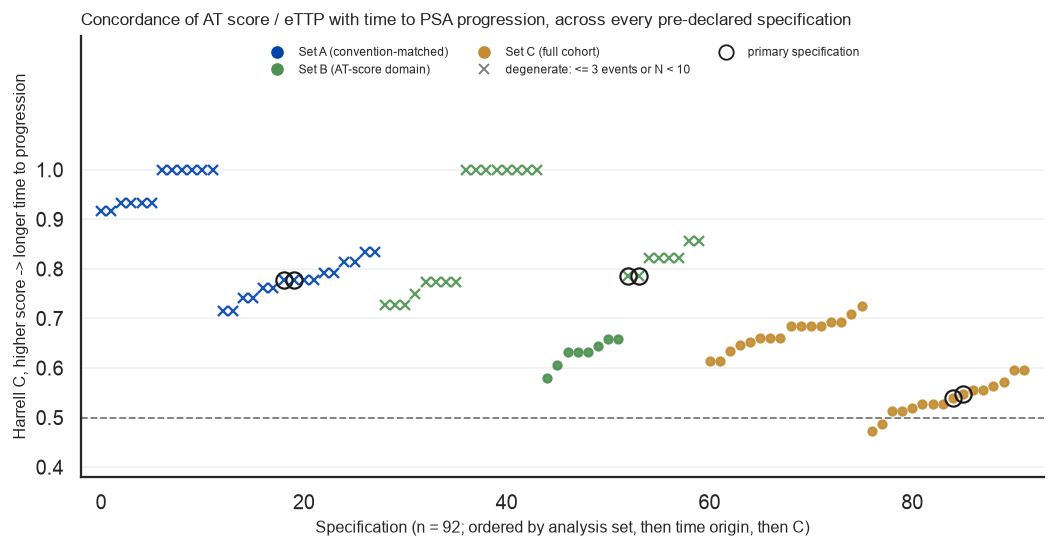

In [14]:
fig, ax = plt.subplots(figsize=(8.2, 4.3))
ok_s = ok.sort_values(["set", "origin", "C"]).reset_index(drop=True)
cmap = {"A": BLUE, "B": GREEN, "C": GOLD}
for i, r in ok_s.iterrows():
    ax.plot(i, r.C, "o" if not r.degenerate else "x", color=cmap[r.set], ms=4.4 if not r.degenerate else 5.5, mew=1.3, alpha=0.9)
prim_rows = ok_s[(ok_s.origin == "treatment") & (ok_s.drug == PRIMARY_DRUG) & (ok_s.priors == "Zhang-style") & (ok_s.outcomes == "TSV as supplied")]
for i, r in prim_rows.iterrows(): ax.plot(i, r.C, "o", mfc="none", mec="k", ms=9, mew=1.2)
ax.axhline(0.5, color=GREY, ls="--", lw=1); ax.set_ylim(0.38, 1.27); ax.set_yticks(np.arange(0.4, 1.01, 0.1)); ax.set_xlim(-2, len(ok_s) + 1)
ax.set_xlabel(f"Specification (n = {len(ok_s)}; ordered by analysis set, then time origin, then C)"); ax.set_ylabel("Harrell C, higher score -> longer time to progression")
ax.set_title("Concordance of AT score / eTTP with time to PSA progression, across every pre-declared specification", loc="left")
h = [plt.Line2D([], [], marker="o", ls="", color=c, label=l) for l, c in [("Set A (convention-matched)", BLUE), ("Set B (AT-score domain)", GREEN), ("Set C (full cohort)", GOLD)]]
h += [plt.Line2D([], [], marker="x", ls="", color=GREY, label="degenerate: <= 3 events or N < 10"), plt.Line2D([], [], marker="o", mfc="none", mec="k", ls="", ms=8, label="primary specification")]
ax.legend(handles=h, fontsize=6.6, loc="upper center", ncol=3); ax.grid(axis="y", alpha=0.25)
fig.tight_layout(); fig.savefig(os.path.join(OUT, "castrate_sensitive_spec_curve.png")); plt.show()

**Reading the grid.** The direction is protective in 90 of 92 estimable cells, but that mostly reflects the cells being re-analyses of the same 16 patients, not 92 independent confirmations. No cell has a Wald P below .05 (minimum .088). 25 cells have a one-sided permutation P < .05 and **24 of those are degenerate** (3 events or fewer, or N below 10, with Cox HR ≈ 0). The strongest cells (C = 1.0) all use the literal first-PSA time origin, under which 7 of 16 patients fall above the pole and are excluded. In the full cohort the result depends on the time origin: median C = 0.53 (range 0.47–0.60) with the treatment origin, versus 0.67 (0.61–0.73) with the first-PSA origin (best Wald P = .089). The pre-declared primary cell (circled) is the null one. The grid is a map of specification sensitivity, not a search for the best cell.

## 8. Why the AT score carries so little signal here

What the fitted turnover tracks (n = 16):
  Spearman(turnover, Baseline_PSA                ) = +0.559   P = 0.024   (n = 16)
  Spearman(turnover, PSA_Nadir                   ) = +0.108   P = 0.690   (n = 16)
  Spearman(turnover, nadir_relative_to_baseline  ) = -0.521   P = 0.039   (n = 16)
  Spearman(turnover, Time_to_Nadir               ) = +0.165   P = 0.542   (n = 16)
  Spearman(turnover, PSA_Doubling_Time_days      ) = +0.571   P = 0.041   (n = 13)


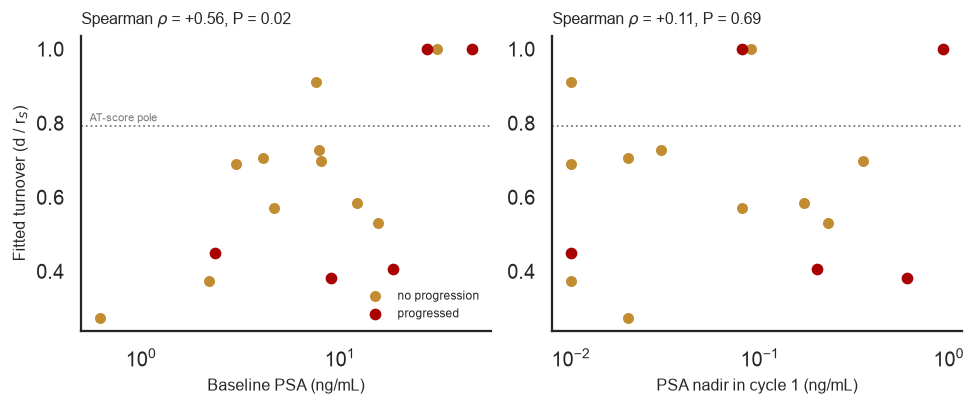

In [15]:
print("What the fitted turnover tracks (n = 16):")
for c in ("Baseline_PSA", "PSA_Nadir", "nadir_relative_to_baseline", "Time_to_Nadir", "PSA_Doubling_Time_days"):
    s = M[["turnover", c]].dropna(); r, p = spearmanr(s.turnover, s[c])
    print(f"  Spearman(turnover, {c:28s}) = {r:+.3f}   P = {p:.3f}   (n = {len(s)})")
fig, axs = plt.subplots(1, 2, figsize=(7.6, 3.2))
ev = as_supplied.Event.reindex(M.index).values.astype(bool)
for ax, (col, xl) in zip(axs, [("Baseline_PSA", "Baseline PSA (ng/mL)"), ("PSA_Nadir", "PSA nadir in cycle 1 (ng/mL)")]):
    ax.scatter(M[col][~ev], M.turnover[~ev], color=GOLD, s=26, label="no progression", zorder=3)
    ax.scatter(M[col][ev], M.turnover[ev], color=RED, s=30, label="progressed", zorder=3)
    ax.set_xscale("log"); ax.set_xlabel(xl); ax.axhline(0.792, color=GREY, ls=":", lw=1)
    r, p = spearmanr(M[col], M.turnover); ax.set_title(f"Spearman $\\rho$ = {r:+.2f}, P = {p:.2f}", loc="left", fontsize=8.6)
axs[0].set_ylabel("Fitted turnover (d / r$_S$)"); axs[0].legend(fontsize=6.8, loc="lower right"); axs[0].text(0.55, 0.805, "AT-score pole", fontsize=6.3, color=GREY)
fig.tight_layout(); fig.savefig(os.path.join(OUT, "castrate_sensitive_turnover.png")); plt.show()

**Why the AT score carries little signal here.** Fitted turnover correlates with **baseline PSA** (ρ = +0.56, P = .024) and with the **fold-change decline** (ρ = −0.52 with nadir/baseline, P = .039), but not with the **absolute nadir** (ρ = +0.11, P = .69). Because every patient is normalised to n₀ = 1, a high-baseline patient with a similar absolute nadir shows a larger relative drop and so a higher turnover and a higher AT score. Baseline PSA is itself adversely associated with progression here (HR 2.5 per SD), which pushes the AT score in the wrong direction, while the absolute nadir, the more prognostic quantity in this cohort, is not what turnover tracks. This is a hypothesis consistent with the correlations, not something these data test directly. A similar pattern was found for the Bruchovsky cohort, where turnover tracked the PSA nadir rather than clinical TTP.

## Conclusions

1. **Primary result: null.** In the full cohort, under the pre-declared primary specification, neither the AT score nor the eTTP is associated with PSA progression (HR ≈ 0.9, C ≈ 0.54, all P > .3). The result is the same with the reconciled outcomes.
2. **Not a validation.** Sets that drop high-turnover patients lean protective (C ≈ 0.78) but rest on 3 events and are conditioned on a model-derived exclusion that removes 2 of the 5 events. No Wald P < .05 is reached in any of the 92 estimable specifications.
3. **Power.** Five events cannot distinguish a moderate benefit from none: the 95% CI (0.37–2.30 per SD) excludes only strong protection.
4. **Model fit.** The fixed-parameter model misses the PSA nadir by a median 12.9× on the log scale, and linear R² does not reveal it. In castrate-sensitive disease depth of response is the dominant feature of the first cycle.
5. **The drug-holiday endpoint cannot be assessed here.** Only the first cycle is available, so the fraction of follow-up off treatment (the endpoint supported in Bruchovsky) cannot be computed in this cohort.

## Limitations

* 16 patients, 5 events (6 reconciled); a bivariable model is not estimable.
* Two outcome records disagree between the TSV and the workbook (102, 116). **Please confirm which is correct.**
* The AT score is formally infinite for 4 of 16 patients (turnover above the pole) and these are ranked highest. This is a convention, and it is where half of the events sit among the excluded patients.
* Five baselines are the last pre-treatment PSA rather than a day-0 measurement; the literal time-origin variant changes the full-cohort C from 0.53 to 0.67.
* K is at its upper bound for 14 of 16 patients, so it is not identified; turnover is at its bound for 3.
* The published eTTP cannot be computed, so the eTTP analysed here is the repository's AT50-like analytic form, not the quantity in eTable S8.
* Nothing is corrected for multiplicity. Not tested: freeing the drug-kill rate (the brief fixes the model).


In [16]:
prim.reset_index().to_csv(os.path.join(OUT, "castrate_sensitive_primary_fits.csv"), index=False)
scored.reset_index().to_csv(os.path.join(OUT, "castrate_sensitive_scored.csv"), index=False)
print("saved:", sorted(f for f in os.listdir(OUT) if f.startswith("castrate_sensitive")))

saved: ['castrate_sensitive_comparators.csv', 'castrate_sensitive_fits.png', 'castrate_sensitive_forest.png', 'castrate_sensitive_km.png', 'castrate_sensitive_primary_fits.csv', 'castrate_sensitive_primary_results.csv', 'castrate_sensitive_scored.csv', 'castrate_sensitive_spec_curve.png', 'castrate_sensitive_spec_grid.csv', 'castrate_sensitive_stats.py', 'castrate_sensitive_turnover.png']
